# Fase 02 : Análisis estadístico y descriptivo
**Institución:** Universidad Católica Boliviana "San Pablo"  
**Programa:** Maestría en Ciencia de Datos  
**Autor:** Carlos Andrés Pérez Guzmán  
**Fecha:** Septiembre 2026  

---
**Entorno y Objetivos del Notebook**
> **Nota:** Descripción de los datos con los que se va a trabajar

* **Fase del Proyecto:** Segunda fase
* **Core Tech Stack:** `Python` (Programación general para ciencia de datos)
---

<h3 style="color:#05856d">1. Librerías</h3>
<hr>

In [83]:
import polars as pl
import polars.selectors as cs
import s_01_functions as fn_01
from pyprojroot import here

<h3 style="color:#05856d">2. Carga de información</h3>
<hr>

Carga de datos limpios

In [84]:
df_01 = pl.read_parquet(source = here()/'01_cleaned_data'/'df_01.parquet')
df_01.glimpse()

Rows: 964207
Columns: 11
$ bottle_volume_ml   <str> '750.0', '1750.0', '375.0', '50.0', '1750.0', '375.0', '375.0', '750.0', '750.0', '50.0'
$ category_name      <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc            <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ item_no            <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on        <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack               <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ period_ordered_on  <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02
$ prod

<h3 style="color:#05856d">3. Análisis descriptivo</h3>
<hr>

<h4 style="color:#05856d">3.1. Variables categóricas</h4>

In [85]:
# Variables categóricas
df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') ).glimpse()

# Vriables numéricas y de fecha
df_01.select(cs.numeric() | cs.by_name('ordered_on')).glimpse()

Rows: 964207
Columns: 5
$ bottle_volume_ml  <str> '750.0', '1750.0', '375.0', '50.0', '1750.0', '375.0', '375.0', '750.0', '750.0', '50.0'
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ period_ordered_on <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02
$ store_no          <cat> 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296

Rows: 964207
Columns: 5
$ item_no        <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on    <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-

<h5 style="font-weight: bold">Categoría del producto</h5>

Cantidad de órdenes o pedidos

In [86]:
df_01.\
    get_column('category_name').\
    value_counts(name = 'count_0', sort = True).\
    with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )

category_name,count_0,ptc_0
cat,u32,f64
"""AMERICAN VODKAS""",150163,0.155737
"""CANADIAN WHISKIES""",94229,0.097727
"""STRAIGHT BOURBON WHISKIES""",79556,0.082509
"""WHISKEY LIQUEUR""",72930,0.075637
"""100% AGAVE TEQUILA""",56061,0.058142
…,…,…
"""NEUTRAL GRAIN SPIRITS""",1425,0.001478
"""MEZCAL""",1116,0.001157
"""SPECIAL ORDER ITEMS""",328,0.00034


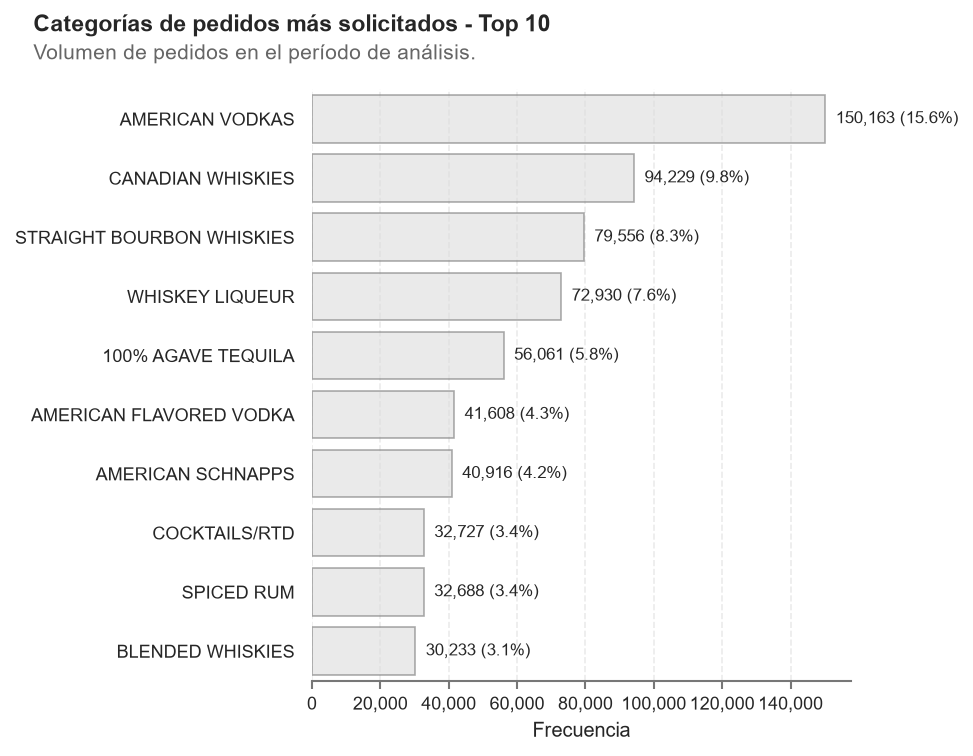

Guardado como: "s_04_01_top_10_categorias.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_01_top_10_categorias.png')

In [87]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'category_name',
    top_param = 10,
    suptitle_param = 'Categorías de pedidos más solicitados - Top 10',
    text_param = 'Volumen de pedidos en el período de análisis.',
    file_param = 's_04_01_top_10_categorias.png',
    show_param = True )

Cantidad de botellas demandadas

In [88]:
( df_01
    .get_column('category_name')
    .value_counts(name = 'count_0', sort = True)
    .with_columns((pl.col('count_0') / pl.sum('count_0')).alias('ptc_0'))
    .sort( by = ['count_0'], descending = [True] )
    )

category_name,count_0,ptc_0
cat,u32,f64
"""AMERICAN VODKAS""",150163,0.155737
"""CANADIAN WHISKIES""",94229,0.097727
"""STRAIGHT BOURBON WHISKIES""",79556,0.082509
"""WHISKEY LIQUEUR""",72930,0.075637
"""100% AGAVE TEQUILA""",56061,0.058142
…,…,…
"""NEUTRAL GRAIN SPIRITS""",1425,0.001478
"""MEZCAL""",1116,0.001157
"""SPECIAL ORDER ITEMS""",328,0.00034


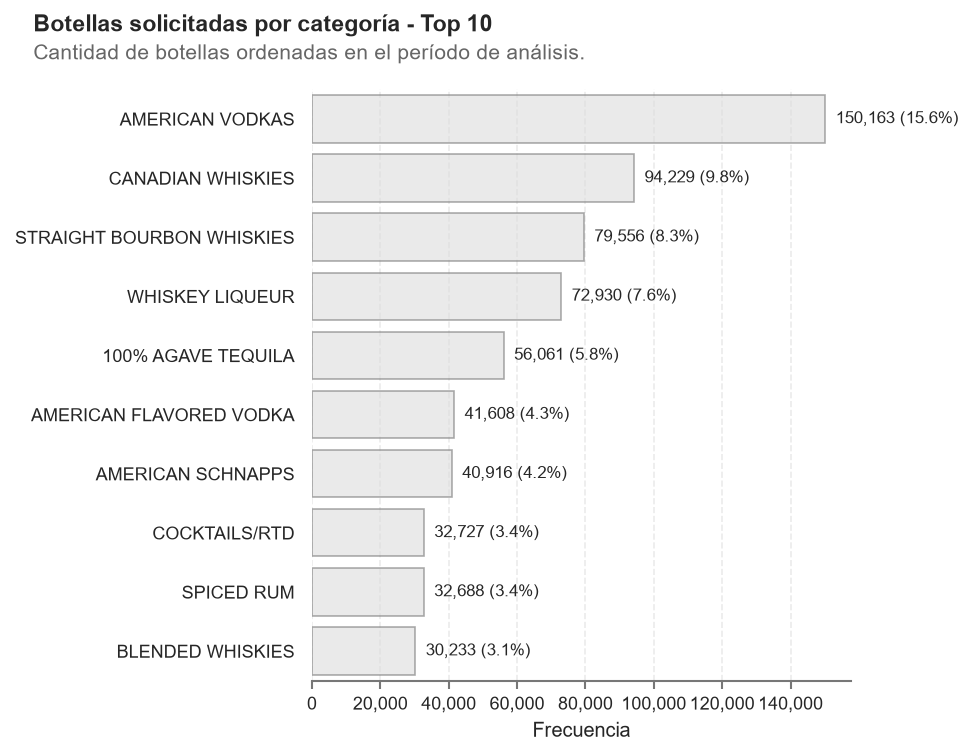

Guardado como: "s_04_02_top_10_categorias.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_02_top_10_categorias.png')

In [89]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'category_name',
    top_param = 10,
    suptitle_param = 'Botellas solicitadas por categoría - Top 10',
    text_param = 'Cantidad de botellas ordenadas en el período de análisis.',
    file_param = 's_04_02_top_10_categorias.png',
    show_param = True )

<h5 style="font-weight: bold">Descripción del producto</h5>

In [90]:
df_01.\
    get_column('im_desc').\
    value_counts(name = 'count_0', sort = True).\
    with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )

im_desc,count_0,ptc_0
cat,u32,f64
"""TITOS HANDMADE VODKA""",32326,0.033526
"""FIREBALL CINNAMON WHISKEY""",23670,0.024549
"""BLACK VELVET""",23216,0.024078
"""HAWKEYE VODKA""",21414,0.022209
"""FIREBALL CINNAMON WHISKEY MINI…",13497,0.013998
…,…,…
"""ANGOSTURA 5YR GOLD RUM""",1,0.000001
"""HA OLD FORESTER SINGLE BARREL …",1,0.000001
"""CM OBTAINIUM BLENDED WHISKEY""",1,0.000001


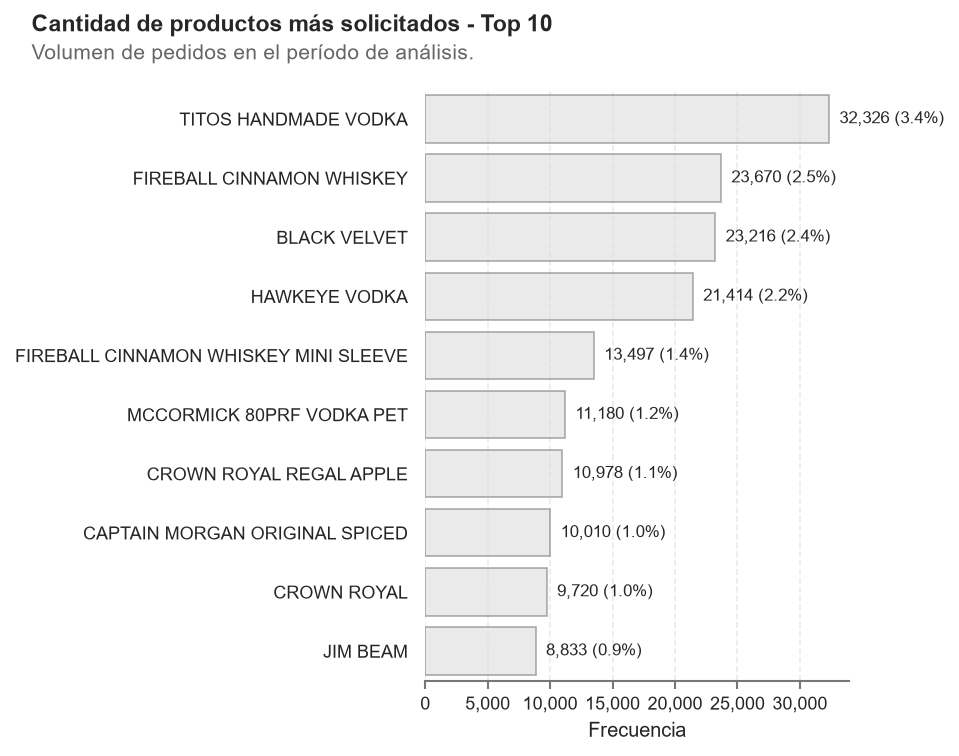

Guardado como: "s_04_03_top_10_productos.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_03_top_10_productos.png')

In [91]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'im_desc',
    top_param = 10,
    suptitle_param = 'Cantidad de productos más solicitados - Top 10',
    text_param = 'Volumen de pedidos en el período de análisis.',
    file_param = 's_04_03_top_10_productos.png',
    show_param = True )

<h5 style="font-weight: bold">Tipo de botellas en las órdenes</h5>

Aunque medir mililitros puede conducir a variables continuas, las botellas almacenan (en general) volúmenes estándar. Esta característica lleva a que esta variable sea tratada de forma categórica para el caso de estudio.

Dentro del dataframe existen 13 tipos de botellas diferencias por su tamaño.

In [92]:
df_01.get_column('bottle_volume_ml').n_unique()

13

In [93]:
df_01.\
    get_column('bottle_volume_ml').\
    value_counts(name = 'count_0', sort = True).\
    with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )

bottle_volume_ml,count_0,ptc_0
str,u32,f64
"""750.0""",393380,0.407983
"""1750.0""",162233,0.168255
"""50.0""",150624,0.156215
"""375.0""",113959,0.118189
"""1000.0""",83305,0.086397
…,…,…
"""25.0""",729,0.000756
"""3000.0""",121,0.000125
"""20.0""",90,0.000093


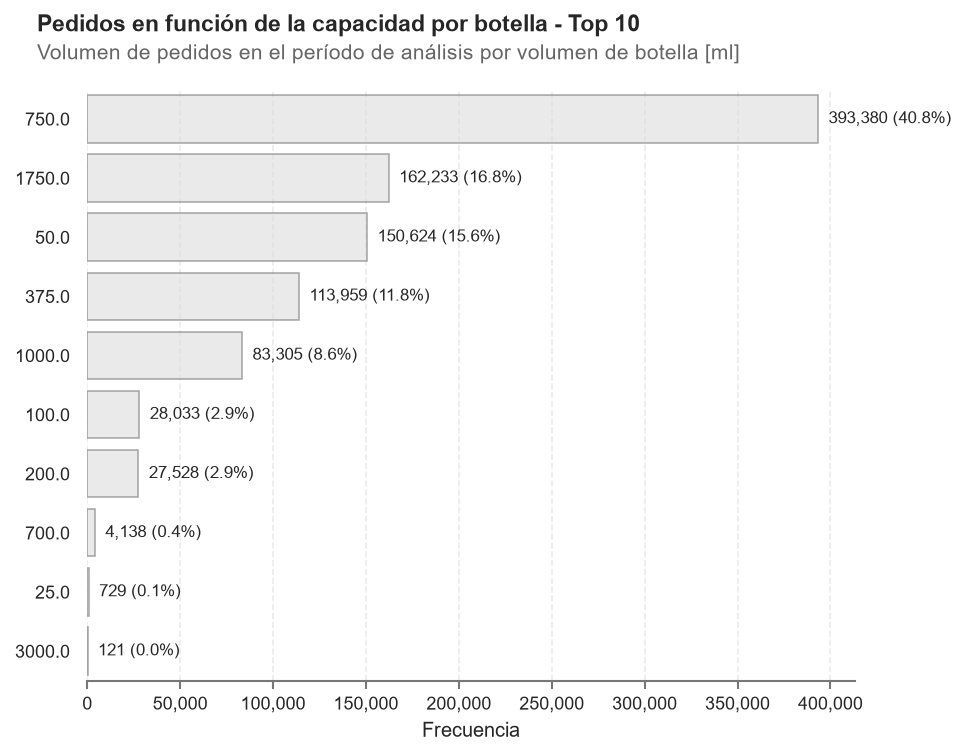

Guardado como: "s_04_04_bottle_volume_ml.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_04_bottle_volume_ml.png')

In [94]:
fn_01.plot_cat_function_01(
    df_param = df_01,
    column_param = 'bottle_volume_ml',
    top_param = 10,
    suptitle_param = 'Pedidos en función de la capacidad por botella - Top 10',
    text_param = 'Volumen de pedidos en el período de análisis por volumen de botella [ml]',
    file_param = 's_04_04_bottle_volume_ml.png',
    show_param = True )

<h4 style="color:#05856d">3.2. Variables numéricas y de fecha</h4>

¿Cuáles son las variables numéricas y de fecha disponibles?

In [95]:
# Variables categóricas
df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') ).glimpse()

# Vriables numéricas y de fecha
df_01.select(cs.numeric() | cs.by_name('ordered_on')).glimpse()

Rows: 964207
Columns: 5
$ bottle_volume_ml  <str> '750.0', '1750.0', '375.0', '50.0', '1750.0', '375.0', '375.0', '750.0', '750.0', '50.0'
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ period_ordered_on <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02
$ store_no          <cat> 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296

Rows: 964207
Columns: 5
$ item_no        <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on    <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-

¿Cuál es el espacio de tiempo en el cual se capturaron los datos?

In [96]:
print(f"Fecha más antigua disponible: {df_01.get_column('ordered_on').min()}")
print(f"Fecha más actual disponible: {df_01.get_column('ordered_on').max()}")

Fecha más antigua disponible: 2026-01-01
Fecha más actual disponible: 2026-05-30


¿Cuál es la distribución de las botellas ordenadas por pedido?

Para dibujar la distribución primero es necesario agrupar la cantidad de botellas compradas por día

Los pedidos manejan altos volúmenes de demanda. Existen, po lo menos 70 días, donde se ordenaron más de 100,000 botellas

In [97]:
df_01.group_by('ordered_on').agg(pl.sum('sales_bottles')).select('sales_bottles').describe()

statistic,sales_bottles
str,f64
"""count""",116.0
"""null_count""",0.0
"""mean""",102052.922414
"""std""",32359.577634
"""min""",96.0
"""25%""",95102.0
"""50%""",109199.0
"""75%""",119795.0
"""max""",170571.0


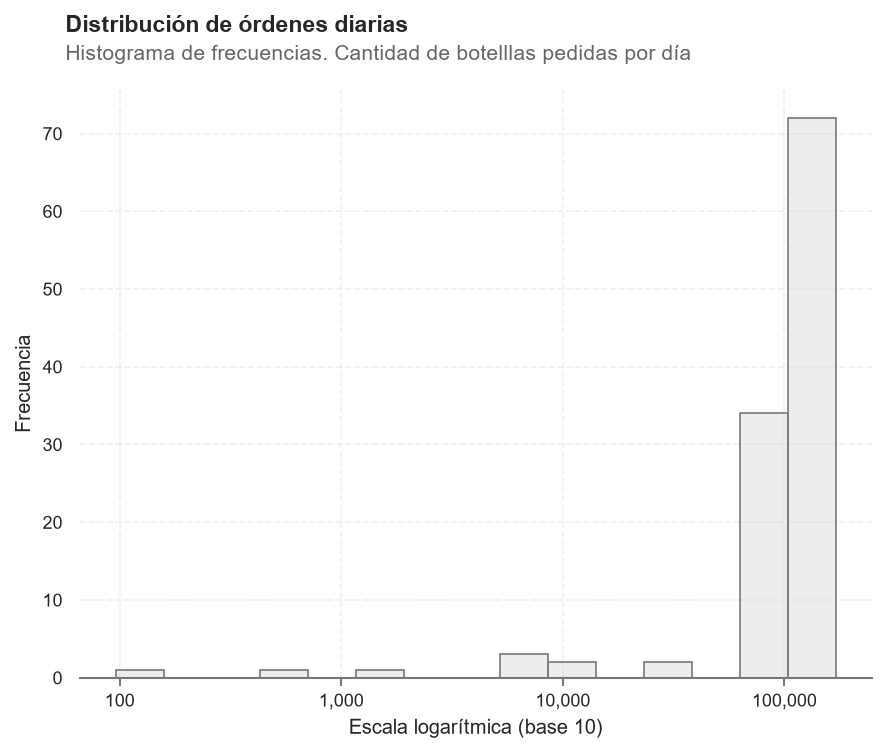

Guardado como: "s_04_05_hist_botellas.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_05_hist_botellas.png')

In [98]:
fn_01.plot_cat_function_02(
    df_param = df_01.group_by('ordered_on').agg(pl.sum('sales_bottles')),
    df_var = 'sales_bottles',
    bins_param = 15,
    suptitle_param = 'Distribución de órdenes diarias',
    text_param = 'Histograma de frecuencias. Cantidad de botelllas pedidas por día',
    file_param = 's_04_05_hist_botellas.png',
    show_param = True)

¿Cuál es la distribución de los ingresos por pedido diario?

Para dibujar la distribución primero es necesario agrupar la cantidad de ingresos por día

Al menos en 50 días se generaron ingresos por encima de un millón de dólares

In [99]:
df_01.group_by('ordered_on').agg(pl.sum('sales_dollars')).select('sales_dollars').describe()

statistic,sales_dollars
str,f64
"""count""",116.0
"""null_count""",0.0
"""mean""",1.3891e6
"""std""",450554.135384
"""min""",3167.04
"""25%""",1.2905e6
"""50%""",1.4650e6
"""75%""",1.6522e6
"""max""",2.2593e6


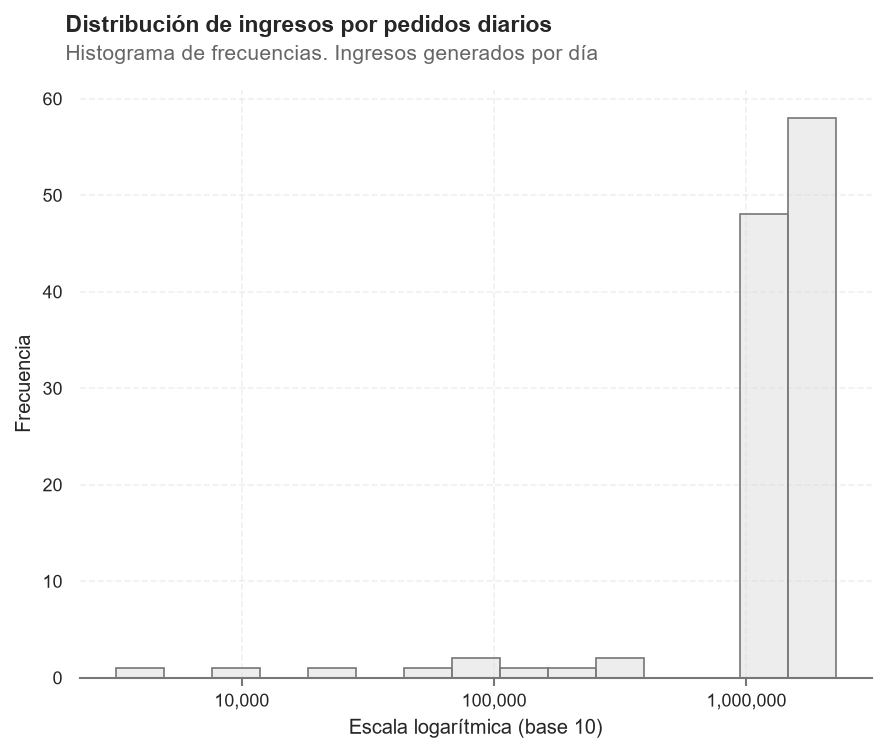

Guardado como: "s_04_06_hist_ingresos.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_06_hist_ingresos.png')

In [100]:
fn_01.plot_cat_function_02(
    df_param = df_01.group_by('ordered_on').agg(pl.sum('sales_dollars')),
    df_var = 'sales_dollars',
    bins_param = 15,
    suptitle_param = 'Distribución de ingresos por pedidos diarios',
    text_param = 'Histograma de frecuencias. Ingresos generados por día',
    file_param = 's_04_06_hist_ingresos.png',
    show_param = True)

<h3 style="color:#05856d">4. Análisis relacional</h3>
<hr>

¿Cuáles son las variables numéricas y de fecha disponibles?

In [101]:
# Variables categóricas
df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') ).glimpse()

# Vriables numéricas y de fecha
df_01.select(cs.numeric() | cs.by_name('ordered_on')).glimpse()

Rows: 964207
Columns: 5
$ bottle_volume_ml  <str> '750.0', '1750.0', '375.0', '50.0', '1750.0', '375.0', '375.0', '750.0', '750.0', '50.0'
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ period_ordered_on <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02
$ store_no          <cat> 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296, 4296

Rows: 964207
Columns: 5
$ item_no        <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on    <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-

<h4 style="color:#05856d">4.1. Asociaciones</h4>

Se busca analizar el nivel de asociación basado en la frecuencia u ocurrencia.

¿Exite una posible asociación entre el tipo de presentación (botella) y alguna categoría de producto? 

In [77]:
( df_01
    .group_by('category_name')
    .agg(pl.sum('sales_bottles').alias('total_bottles'))
    .sort( by = ['total_bottles'], descending = [True])
    )

category_name,total_bottles
cat,i64
"""AMERICAN VODKAS""",2549586
"""WHISKEY LIQUEUR""",1893698
"""CANADIAN WHISKIES""",1075720
"""STRAIGHT BOURBON WHISKIES""",672149
"""SPICED RUM""",514853
…,…
"""AGED DARK RUM""",15718
"""NEUTRAL GRAIN SPIRITS""",10206
"""MEZCAL""",6203


In [72]:

( df_01
    .group_by(['category_name', 'bottle_volume_ml'])
    .len(name = 'count')
    .sort(['category_name', 'bottle_volume_ml'])
    .pivot(
        on = 'bottle_volume_ml',
        index = 'category_name',
        values = 'count' )
    .fill_null(0)
    )

category_name,100.0,1000.0,1750.0,200.0,375.0,50.0,700.0,750.0,25.0,3750.0,4500.0,20.0,3000.0
cat,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
"""100% AGAVE TEQUILA""",305,2152,1936,1882,10128,4726,215,34717,0,0,0,0,0
"""AGED DARK RUM""",0,191,112,0,64,0,3,2578,0,0,0,0,0
"""AMERICAN BRANDIES""",500,1418,2226,2038,3158,777,0,8237,0,0,0,0,0
"""AMERICAN CORDIALS & LIQUEUR""",1180,1161,331,1,0,15212,0,7397,0,0,0,0,0
"""AMERICAN DISTILLED SPIRIT SPEC…",0,4,0,1,230,105,0,1596,0,0,0,0,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""TEMPORARY & SPECIALTY PACKAGES""",0,892,191,13,654,1174,1152,18710,0,2,0,0,121
"""TENNESSEE WHISKIES""",226,2602,1973,887,3380,6216,141,11897,0,0,0,0,0
"""TRIPLE SEC""",0,2651,0,0,0,0,0,423,0,0,0,0,0


<h4 style="color:#05856d">4.2. Correlaciones</h4>

<h4 style="color:#05856d">4.3. Comparaciones</h4>

<h3 style="color:#05856d">5. Selección del caso de modelamiento</h3>
<hr>

¿Cuál es el producto que genera más ingresos? 

In [ ]:
analysis_01 = (
    df_01
    .group_by(['product_code'])
    .agg(

        # 1. ¿Qué productos están involucrado?
        pl.col('category_name').unique().str.join(', '),

        # 2. ¿Cuántas botellas se han vendido en la historia de este producto?
        pl.sum('sales_bottles').alias('volumen_botellas'),

        # 3. Ingresos genereados por la venta de botellas (expresado en miles)
        (pl.sum('sales_dollars')/1000).alias('sales_miles'),
        
        # 4. ¿En cuántos días únicos alguien compró al menos 1 botella?
        pl.n_unique('ordered_on').alias('frecuencia_dias_demanda'),
        pl.n_unique('ordered_on').cut(
            breaks = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
            labels = [
                '0-10 días', '10-20 días', '20-30 días', '30-40 días', '40-50 días', 
                '50-60 días', '60-70 días', '70-80 días', '80-90 días', 
                '90-100 días', '>100 días'],
            left_closed = False ).alias('frecuencia_dias_demanda_cat') )
    
    # Ordenar por los que tienen demanda más constante, y luego por volumen
    .sort(['frecuencia_dias_demanda', 'sales_miles'], descending = [True, True])
)

print(f"Existen {df_01.n_unique(subset = ['product_code'])} productos únicos en el dataset.")
print(analysis_01.shape)
analysis_01.head()

Existen 4047 productos únicos en el dataset.
(4047, 6)


product_code,category_name,volumen_total_botellas,sales_miles,frecuencia_dias_demanda,frecuencia_dias_demanda_cat
str,str,i64,f64,u32,enum
"""PRD_001358""","""AMERICAN VODKAS""",195811,3869.0174,115,""">100 días"""
"""PRD_000201""","""CANADIAN WHISKIES""",160082,2760.654,115,""">100 días"""
"""PRD_001255""","""AMERICAN VODKAS""",252335,695.91244,115,""">100 días"""
"""PRD_001687""","""IMPORTED BRANDIES""",35674,614.54276,115,""">100 días"""
"""PRD_001142""","""IMPORTED VODKAS""",11455,194.735,115,""">100 días"""


¿Cómo se concentra el ingreso del mejor producto a lo largo de las tiendas?

In [64]:
analysis_02 = (
    df_01
    .filter(pl.col('product_code') == 'PRD_001358')
    .group_by('store_no')
    .agg(

        # 1. ¿Cuántas botellas se han vendido en la historia de este producto?
        pl.sum('sales_bottles').alias('volumen_botellas'),

        # 2. Ingresos genereados por la venta de botellas (expresado en miles)
        (pl.sum('sales_dollars')/1000).alias('sales_miles'),
        
        # 3. ¿En cuántos días únicos alguien compró al menos 1 botella?
        pl.n_unique('ordered_on').alias('frecuencia_dias_demanda'),
        pl.n_unique('ordered_on').cut(
            breaks = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
            labels = [
                '0-10 días', '10-20 días', '20-30 días', '30-40 días', '40-50 días', 
                '50-60 días', '60-70 días', '70-80 días', '80-90 días', 
                '90-100 días', '>100 días'],
            left_closed = False ).alias('frecuencia_dias_demanda_cat') )

    # Aporte porcentual
    .with_columns(
        ( (pl.col('sales_miles') / pl.col('sales_miles').sum() ) * 100).alias('sales_miles_pct') )

    # Ordenar por los que tienen demanda más constante, y luego por volumen
    #.sort(['frecuencia_dias_demanda', 'sales_miles'], descending = [True, True])
    .sort(['sales_miles'], descending = [True])
    )

print(f"Existen {analysis_02.n_unique(subset = ['store_no'])} tiendas que solicitaron el producto de mejor desempeño.")
print(f"Ventas totales en miles de dólares: {analysis_02.get_column('sales_miles').sum():,.2f}.")
print(analysis_02.shape)
analysis_02

Existen 820 tiendas que solicitaron el producto de mejor desempeño.
Ventas totales en miles de dólares: 3,869.02.
(820, 6)


store_no,volumen_botellas,sales_miles,frecuencia_dias_demanda,frecuencia_dias_demanda_cat,sales_miles_pct
i64,i64,f64,u32,enum,f64
2633,26412,521.8986,6,"""0-10 días""",13.489177
4829,22428,443.17184,46,"""40-50 días""",11.454377
5916,11640,230.0036,37,"""30-40 días""",5.944755
2512,9360,184.9534,13,"""10-20 días""",4.780371
3773,7908,156.2578,38,"""30-40 días""",4.038695
…,…,…,…,…,…
5779,1,0.01976,1,"""0-10 días""",0.000511
4201,1,0.01976,1,"""0-10 días""",0.000511
10761,1,0.01976,1,"""0-10 días""",0.000511


from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import polars as pl
from pyprojroot import here
import seaborn as sns


def plot_boxplot_log_01(
    *,
    df_param: pl.DataFrame,
    x_col: str,
    y_col: str,
    suptitle_param: str,
    text_param: str,
    file_param: str,
    show_param: bool = True
) -> Path:
    """
    Genera, personaliza y exporta un boxplot con escala logarítmica en el eje Y.
    """
    # 1. Configuración del tema Seaborn
    sns.set_theme(
        context = 'paper',
        style = 'white',
        rc = {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.3}
    )

    # 2. Creación del lienzo
    fig, ax = plt.subplots(figsize = (7, 4.5))

    # 3. Gráfico boxplot
    sns.boxplot(
        data = df_param,
        x = x_col,
        y = y_col,
        color = '#DCDCDC',
        linecolor = '#555555',
        fliersize = 2.5,
        flierprops = {'markerfacecolor': '#999999', 'markeredgecolor': 'none'},
        width = 0.5,
        ax = ax
    )

    # 4. Escala logarítmica y formato en eje Y
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.yaxis.get_major_formatter().set_scientific(False)

    # 5. Despine y etiquetas de ejes
    sns.despine(ax = ax, offset = 10, trim = True)
    ax.set_xlabel('Período', labelpad = 8)
    ax.set_ylabel('Botellas vendidas (escala log)', labelpad = 8)
    ax.tick_params(axis = 'both', colors = '#555555')

    # 6. Título y subtítulo
    fig.suptitle(
        suptitle_param,
        x = 0.05,
        y = 0.98,
        ha = 'left',
        weight = 'bold',
        size = 11
    )

    fig.text(
        x = 0.05,
        y = 0.93,
        s = text_param,
        ha = 'left',
        fontsize = 9,
        color = '#666666'
    )

    fig.subplots_adjust(top = 0.85)

    # 7. Exportación
    file_destiny = here() / '05_graphs' / file_param
    file_destiny.parent.mkdir(parents = True, exist_ok = True)

    # fig.savefig(
    #     file_destiny,
    #     dpi = 300,
    #     bbox_inches = 'tight',
    #     facecolor = 'white'
    # )

    if show_param:
        plt.show()
    else:
        plt.close(fig)

    print(f'Guardado como: "{file_param}" en 05_graphs')
    return file_destiny

plot_boxplot_log_01(
    df_param = df_01,
    x_col = 'period_ordered_on',
    y_col = 'sales_bottles',
    suptitle_param = 'Distribución de ventas de botellas por período',
    text_param = 'Dispersión y valores atípicos (escala logarítmica en eje Y).',
    file_param = '02_boxplot_ventas_periodo_log.png',
    show_param = True
)